<a href="https://colab.research.google.com/github/nurilhuda05/Pembelajaran_Mesin_2026/blob/main/TG11_244107020004_Muhammad_Nuril_Huda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **PRAKTIKUM 1**

### **Langkah 1 - Import Library**

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns

### **Langkah 2 - Membuat Data Dummy**

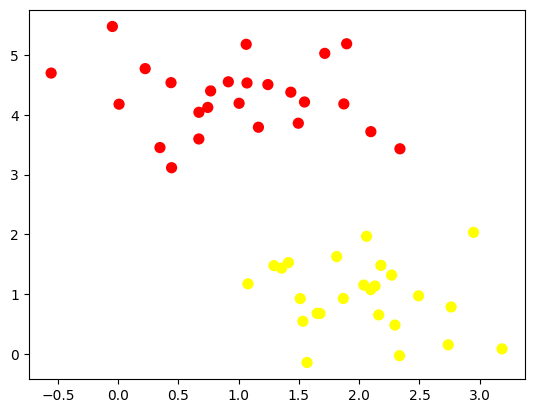

In [24]:
from sklearn.datasets import make_blobs

# Membuat data dengan dua kelas
X, y = make_blobs(
    n_samples=50,
    centers=2,
    random_state=0,
    cluster_std=0.60
)


plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plt.show()

### **Langkah 3 - Membuat Ilustrasi Garis Pemisah**

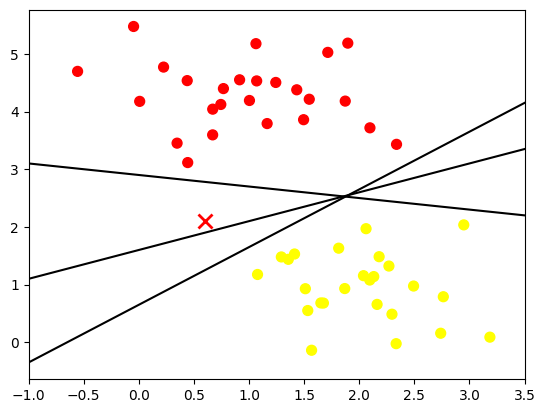

In [25]:
# Rentang sumbu x untuk menggambar garis
xfit = np.linspace(-1, 3.5)

# Plot data dari Langkah 2
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

# Titik data baru 'x'
plt.plot([0.6], [2.1], 'x', color='red', markeredgewidth=2, markersize=10)

# Tiga garis pemisah yang berbeda, dengan format (gradien m, intersep b)
for m, b in [(1, 0.65), (0.5, 1.6), (-0.2, 2.9)]:
    plt.plot(xfit, m * xfit + b, '-k')

# Batas sumbu x
plt.xlim(-1, 3.5)
plt.show()

### **Langkah 4 - Ilustrasi Margin**

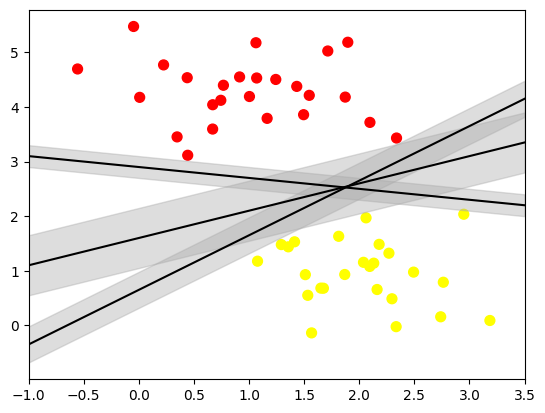

In [26]:
# Membuat rentang nilai untuk garis
xfit = np.linspace(-1, 3.5)

# Menampilkan data
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

# Membuat beberapa garis pemisah dan margin
for m, b, d in [(1, 0.65, 0.33), (0.5, 1.6, 0.55), (-0.2, 2.9, 0.2)]:
    yfit = m * xfit + b
    plt.plot(xfit, yfit, '-k')
    plt.fill_between(
        xfit,
        yfit - d,
        yfit + d,
        edgecolor='none',
        color='#AAAAAA',
        alpha=0.4
    )

# Mengatur batas sumbu X
plt.xlim(-1, 3.5)
plt.show()

### **Langkah 5 - Fitting Model**

#### **5A - Melatih Model SVM**

In [22]:
# Import algoritma SVM
from sklearn.svm import SVC

# Membuat model SVM dengan kernel linear
model = SVC(kernel='linear', C=1E10)

# Melatih model menggunakan data dummy
model.fit(X, y)

SVC(C=10000000000.0, kernel='linear')

#### **5B - Membuat fungsi visualisasi garis pemisah**

In [27]:
# Fungsi untuk menampilkan garis pemisah dan margin
def plot_svc_decision_function(model, ax=None, plot_support=True):

    if ax is None:
        ax = plt.gca()

    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # Membuat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)

    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # Menampilkan garis pemisah dan margin
    ax.contour(
        X, Y, P,
        colors='k',
        levels=[-1, 0, 1],
        alpha=0.5,
        linestyles=['--', '-', '--']
    )

    # Menampilkan support vector
    if plot_support:
        ax.scatter(
            model.support_vectors_[:, 0],
            model.support_vectors_[:, 1],
            s=300,
            linewidth=1,
            facecolors='none'
        )

    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

#### **5C - Menampilkan hasil model SVM**

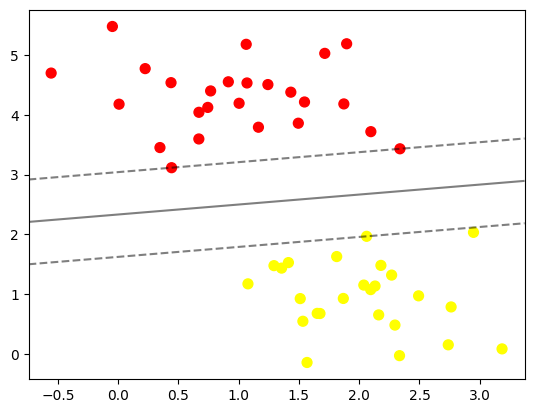

In [29]:
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

plot_svc_decision_function(model)

plt.show()

#### **5D - Melihat Support Vector**

In [30]:
# Menampilkan titik yang menjadi support vector
model.support_vectors_

array([[0.44359863, 3.11530945],
       [2.33812285, 3.43116792],
       [2.06156753, 1.96918596]])

### **Langkah 6 - Membandingkan Model dengan Jumlah Data Berbeda**

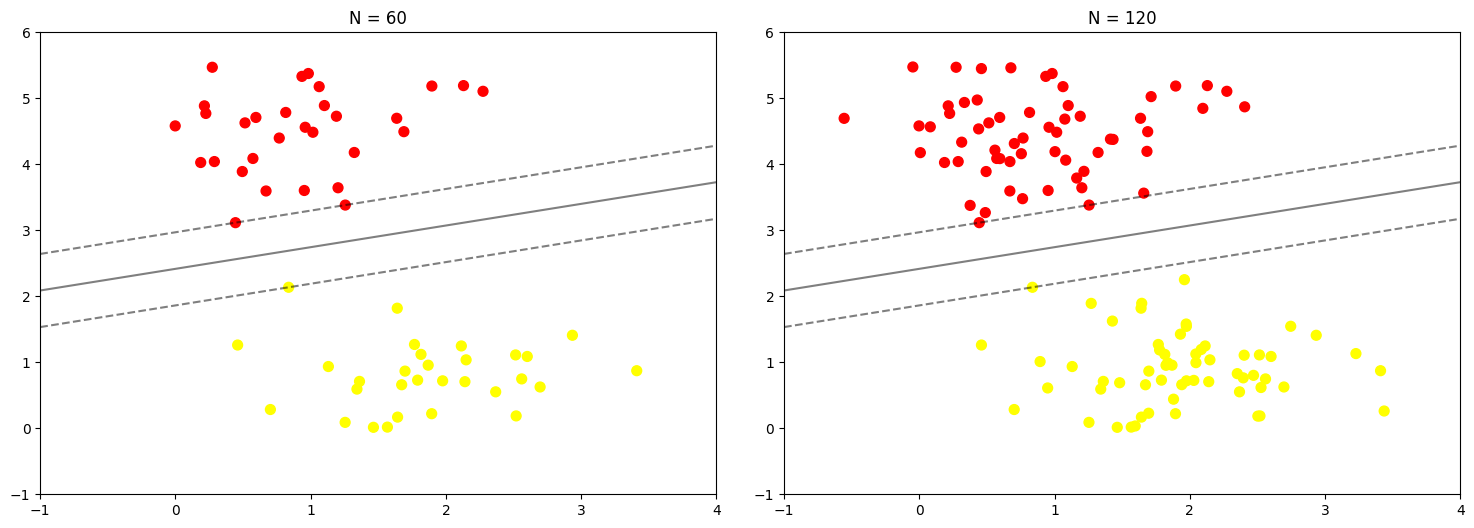

In [31]:
# Fungsi untuk membuat dan menampilkan model SVM
def plot_svm(N=10, ax=None):
    # Membuat 200 data dummy
    X, y = make_blobs(
        n_samples=200,
        centers=2,
        random_state=0,
        cluster_std=0.60
    )

    # Mengambil sejumlah data sesuai N
    X = X[:N]
    y = y[:N]

    # Membuat dan melatih model SVM
    model = SVC(kernel='linear', C=1E10)
    model.fit(X, y)

    # Menampilkan data
    ax = ax or plt.gca()
    ax.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

    # Mengatur batas grafik
    ax.set_xlim(-1, 4)
    ax.set_ylim(-1, 6)

    # Menampilkan garis pemisah dan margin
    plot_svc_decision_function(model, ax)


# Membuat dua grafik perbandingan
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)

# Menampilkan model dengan 60 dan 120 data
for axi, N in zip(ax, [60, 120]):
    plot_svm(N, axi)
    axi.set_title('N = {}'.format(N))

plt.show()

### **Langkah 7 - Interaksi Jumlah Data Menggunakan ipywidgets**

#### **7A - Instalasi library**

In [32]:
!pip install ipywidgets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 47.4 MB/s eta 0:00:00


#### **7B - Membuat tampilan interaktif**

In [37]:
# Import library untuk interaksi
from ipywidgets import interact, fixed

# Menampilkan model dengan pilihan jumlah data
interact(plot_svm, N=[10,50,100,150,200], ax=fixed(None))

plt.show()

interactive(children=(Dropdown(description='N', options=(10, 50, 100, 150, 200), value=10), Output()), _dom_cl…

# **PRAKTIKUM 2**

### **Langkah 1 - Ilustrasi Data Non-Linier**

#### **1A - Import Library**

In [38]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.svm import SVC

#### **1B - Membuat Kembali Fungsi Plotting**

In [39]:
# Fungsi untuk menampilkan garis pemisah dan margin
def plot_svc_decision_function(model, ax=None, plot_support=True):

    if ax is None:
        ax = plt.gca()

    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # Membuat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)

    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # Menampilkan garis pemisah dan margin
    ax.contour(
        X, Y, P,
        colors='k',
        levels=[-1, 0, 1],
        alpha=0.5,
        linestyles=['--', '-', '--']
    )

    # Menampilkan support vector
    if plot_support:
        ax.scatter(
            model.support_vectors_[:, 0],
            model.support_vectors_[:, 1],
            s=300,
            linewidth=1,
            facecolors='none'
        )

    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

#### **1C - Membuat Data Dummy Non-Linier**

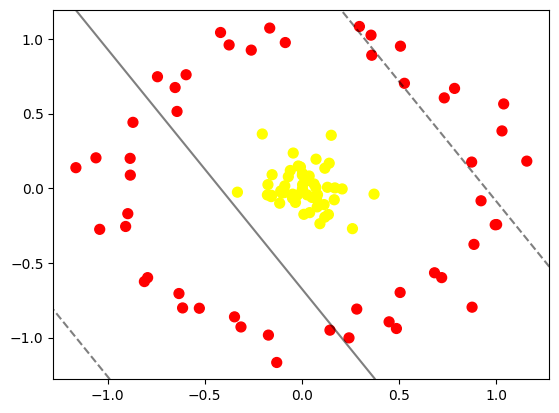

In [44]:
# Import library untuk membuat data lingkaran
from sklearn.datasets import make_circles

# Membuat data dummy non-linier
X, y = make_circles(
    n_samples=100,
    factor=0.1,
    noise=0.1,
    random_state=42
)

# Melatih SVM dengan kernel linear
clf = SVC(kernel='linear')
clf.fit(X, y)

# Menampilkan visualisasi data
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

# Menampilkan garis pemisah
plot_svc_decision_function(clf, plot_support=False)

plt.show()

Hasil grafik yang diperoleh berbeda dengan modul karena pada kode ini ditambahkan parameter random_state=42, sedangkan modul tidak menggunakannya. Parameter tersebut membuat data yang dihasilkan tetap sama setiap kali kode dijalankan. Tanpa random_state, data dapat berubah setiap kali dijalankan.

#### **1D - Visualisasi Data dalam Bentuk 3D**

In [58]:
# Import library untuk visualisasi 3D dan interaksi
from mpl_toolkits import mplot3d
from ipywidgets import interact, fixed

# Menghitung proyeksi radial
r = np.exp(-(X**2).sum(1))

# Membuat fungsi visualisasi 3D
def plot_3D(elev=30, azim=30, X=X, y=y):
    ax = plt.subplot(projection='3d')

    ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=50, cmap='autumn')

    ax.view_init(elev=elev, azim=azim)

    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('r')


# Menampilkan grafik interaktif
interact(
    plot_3D,
    elev=[-90, 45, 30, 20, 10],
    azim=(-180, 180),
    X=fixed(X),
    y=fixed(y)
)

plt.show()

interactive(children=(Dropdown(description='elev', index=2, options=(-90, 45, 30, 20, 10), value=30), IntSlide…

### **Langkah 2 - Fitting Model dengan Kernel RBF**

#### **2A - Melatih model SVM**

In [59]:
# Membuat model SVM dengan kernel RBF
clf = SVC(kernel='rbf', C=1E6)

# Melatih model menggunakan data dummy
clf.fit(X, y)

SVC(C=1000000.0)

#### **2B - Menampilkan hasil klasifikasi**

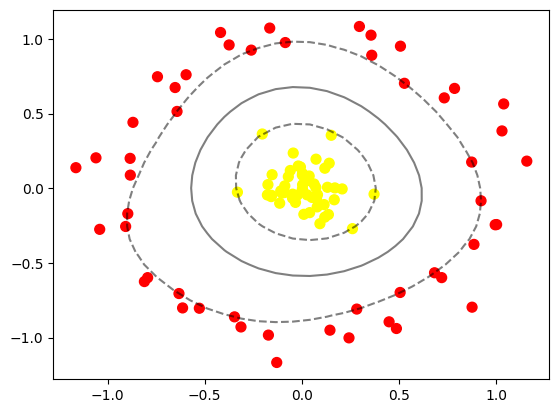

In [60]:
# Menampilkan data
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

# Menampilkan garis pemisah dan margin
plot_svc_decision_function(clf)

# Menampilkan support vector
plt.scatter(
    clf.support_vectors_[:, 0],
    clf.support_vectors_[:, 1],
    s=300,
    linewidth=1,
    facecolors='none'
)

plt.show()

# **PRAKTIKUM 3**

### **Langkah 1 - Import Library dan Buat Fungsi Plotting**

#### **1A - Import library**

In [61]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.svm import SVC
from sklearn.datasets import make_blobs

#### **1B - Membuat fungsi plotting**

In [62]:
# Fungsi untuk menampilkan garis pemisah dan margin
def plot_svc_decision_function(model, ax=None, plot_support=True):

    if ax is None:
        ax = plt.gca()

    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # Membuat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)

    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # Menampilkan garis pemisah dan margin
    ax.contour(
        X, Y, P,
        colors='k',
        levels=[-1, 0, 1],
        alpha=0.5,
        linestyles=['--', '-', '--']
    )

    # Menampilkan support vector
    if plot_support:
        ax.scatter(
            model.support_vectors_[:, 0],
            model.support_vectors_[:, 1],
            s=300,
            linewidth=1,
            facecolors='none'
        )

    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

### **Langkah 2 - Buat Data Dummy**

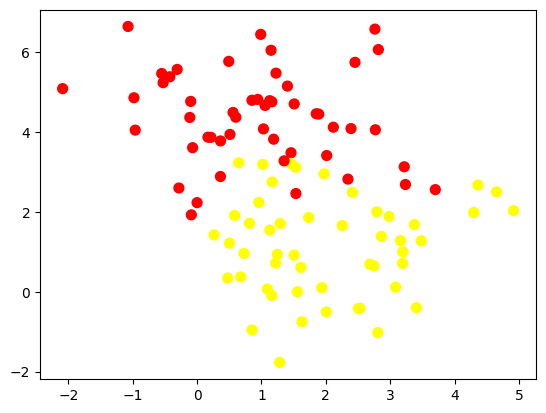

In [63]:
X, y = make_blobs(
    n_samples=100,
    centers=2,
    random_state=0,
    cluster_std=1.2
)

plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plt.show()

### **Langkah 3 - Analisis Dampak Tunning**

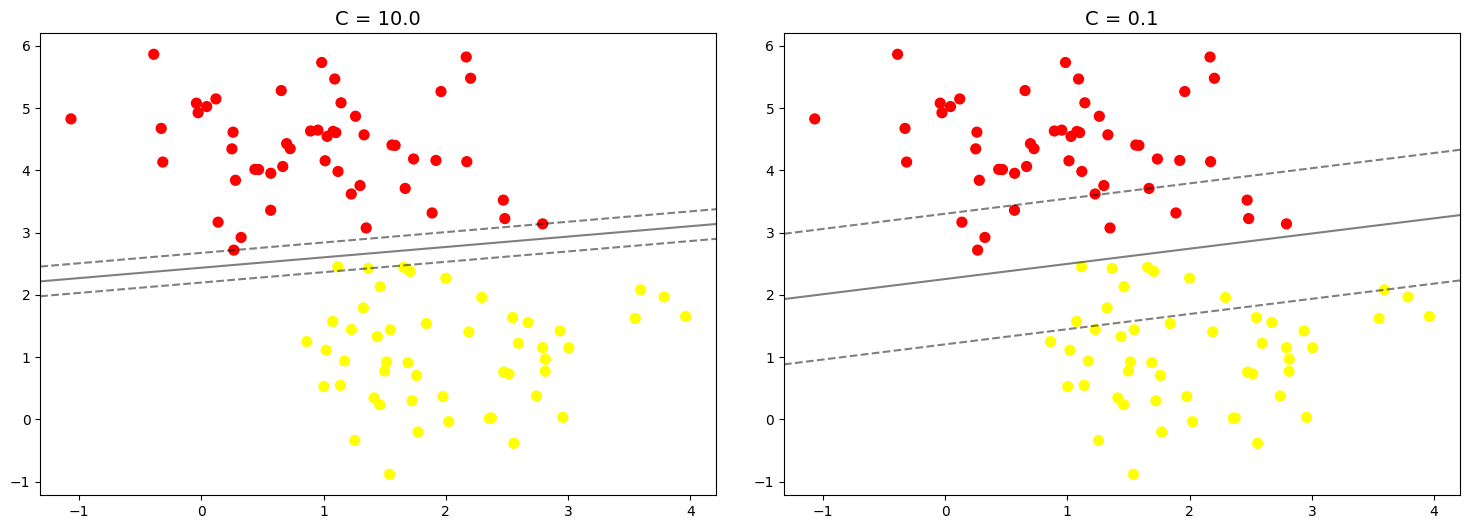

In [64]:
# Membuat dataset dengan 100 data dan 2 kelompok
X, y = make_blobs(
    n_samples=100,
    centers=2,
    random_state=0,
    cluster_std=0.8
)

# Membuat tempat untuk menampilkan 2 grafik
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)

# Membandingkan nilai C = 10.0 dan C = 0.1
for axi, C in zip(ax, [10.0, 0.1]):

    # Membuat dan melatih model SVM dengan kernel linear
    model = SVC(kernel='linear', C=C).fit(X, y)

    # Menampilkan titik data berdasarkan kelompoknya
    axi.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

    # Menampilkan batas pemisah dan margin SVM
    plot_svc_decision_function(model, axi)

    # Menandai support vectors dengan lingkaran kosong
    axi.scatter(
        model.support_vectors_[:, 0],
        model.support_vectors_[:, 1],
        s=300,
        lw=1,
        facecolors='none'
    )

    # Memberikan judul sesuai nilai C
    axi.set_title('C = {0:.1f}'.format(C), size=14)

# Menampilkan kedua grafik
plt.show()

# **PRAKTIKUM 4**

### **Langkah 0 - Unduh Dataset**

In [65]:
from sklearn.datasets import fetch_lfw_people

# Mengunduh dataset dengan minimal 60 foto untuk setiap tokoh
faces = fetch_lfw_people(min_faces_per_person=60)

# Menampilkan nama tokoh yang terdapat dalam dataset
print(faces.target_names)

# Menampilkan jumlah tokoh
print(len(faces.target_names))

# Menampilkan ukuran data citra wajah
print(faces.images.shape)

['Ariel Sharon' 'Colin Powell' 'Donald Rumsfeld' 'George W Bush'
 'Gerhard Schroeder' 'Hugo Chavez' 'Junichiro Koizumi' 'Tony Blair']
8
(1348, 62, 47)


### **Langkah 1 - Inspeksi Citra Wajah**

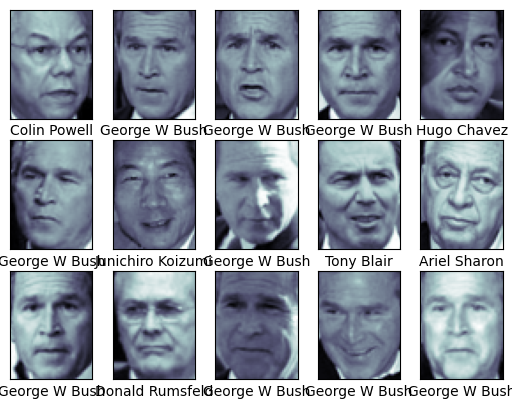

In [72]:
from matplotlib import pyplot as plt

fig, ax = plt.subplots(3, 5)

for i, axi in enumerate(ax.flat):
    axi.imshow(faces.images[i], cmap='bone')

    # Menghilangkan angka pada sumbu gambar
    axi.set(xticks=[], yticks=[])

    # Menampilkan nama tokoh di bawah gambar
    axi.set(xlabel=faces.target_names[faces.target[i]])

### **Langkah 2 - Pra Pengolahan Data Menggunakan PCA**

In [73]:
from sklearn.svm import SVC
from sklearn.decomposition import PCA as RandomizedPCA
from sklearn.pipeline import make_pipeline

# Membuat model PCA dengan 150 komponen
pca = RandomizedPCA(
    n_components=150,
    whiten=True,
    random_state=42
)

# Membuat model SVM dengan kernel RBF
svc = SVC(
    kernel='rbf',
    class_weight='balanced'
)

# Menggabungkan PCA dan SVM dalam satu pipeline
model = make_pipeline(pca, svc)

### **Langkah 3 - Split Data Training dan Testing**

In [74]:
from sklearn.model_selection import train_test_split

# Membagi data menjadi data training dan data testing
Xtrain, Xtest, ytrain, ytest = train_test_split(
    faces.data,
    faces.target,
    random_state=42
)

### **Langkah 4 - Pembuatan Model dan Tuning Hyperparameter**

In [75]:
from sklearn.model_selection import GridSearchCV

# Menentukan kombinasi nilai C dan gamma yang akan diuji
param_grid = {
    'svc__C': [1, 5, 10, 50],
    'svc__gamma': [0.0001, 0.0005, 0.001, 0.005]
}

# Membuat proses pencarian hyperparameter terbaik
grid = GridSearchCV(model, param_grid)

# Melatih model dan mencari kombinasi terbaik
%time grid.fit(Xtrain, ytrain)

# Menampilkan hyperparameter terbaik
print(grid.best_params_)

# Menampilkan skor terbaik dari cross-validation
print(grid.best_score_)

CPU times: user 2min 12s, sys: 146 ms, total: 2min 12s
Wall time: 1min 19s
{'svc__C': 5, 'svc__gamma': 0.001}
0.828893332683022


In [76]:
# Mengambil model dengan hyperparameter terbaik
model = grid.best_estimator_

# Melakukan prediksi pada data testing
yfit = model.predict(Xtest)

### **Langkah 5 - Cek Hasil Prediksi**

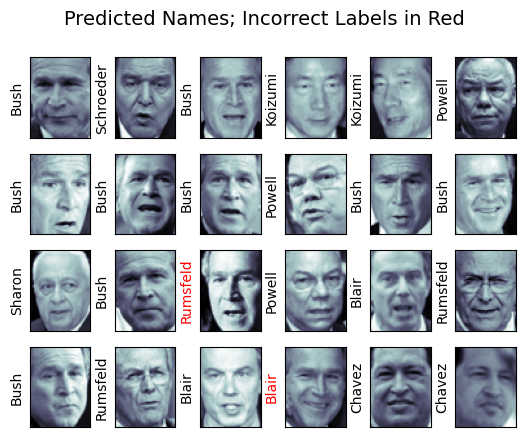

In [77]:
fig, ax = plt.subplots(4, 6)

# Menampilkan 24 gambar wajah
for i, axi in enumerate(ax.flat):
    axi.imshow(Xtest[i].reshape(62, 47), cmap='bone')

    # Menghilangkan angka pada sumbu gambar
    axi.set(xticks=[], yticks=[])

    # Menampilkan nama belakang tokoh hasil prediksi
    # Warna merah menunjukkan prediksi yang salah
    axi.set_ylabel(
        faces.target_names[yfit[i]].split()[-1],
        color='black' if yfit[i] == ytest[i] else 'red'
    )

fig.suptitle('Predicted Names; Incorrect Labels in Red', size=14)

plt.show()

### **Langkah 6 - Cek Performansi Model**

#### **6A - Classification Report**

In [78]:
from sklearn.metrics import classification_report

# Menampilkan laporan performa model
print(classification_report(
    ytest,
    yfit,
    target_names=faces.target_names
))

                   precision    recall  f1-score   support

     Ariel Sharon       0.65      0.87      0.74        15
     Colin Powell       0.83      0.88      0.86        68
  Donald Rumsfeld       0.70      0.84      0.76        31
    George W Bush       0.97      0.80      0.88       126
Gerhard Schroeder       0.76      0.83      0.79        23
      Hugo Chavez       0.93      0.70      0.80        20
Junichiro Koizumi       0.86      1.00      0.92        12
       Tony Blair       0.82      0.98      0.89        42

         accuracy                           0.85       337
        macro avg       0.82      0.86      0.83       337
     weighted avg       0.86      0.85      0.85       337



#### **6B - Confusion Matrix**

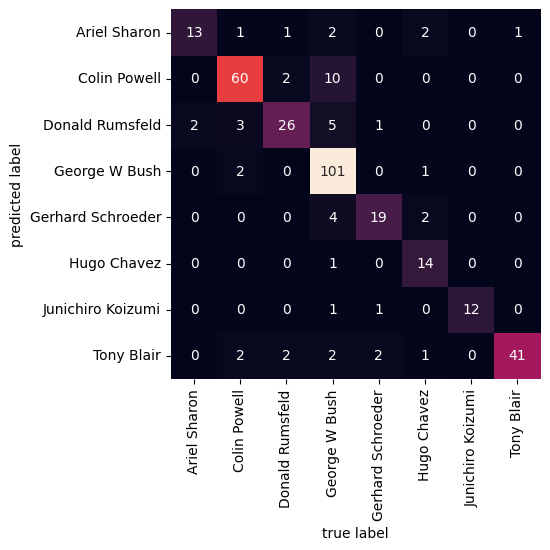

In [79]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

# Membuat confusion matrix
mat = confusion_matrix(ytest, yfit)

# Menampilkan confusion matrix dalam bentuk heatmap
sns.heatmap(
    mat.T,
    square=True,
    annot=True,
    fmt='d',
    cbar=False,
    xticklabels=faces.target_names,
    yticklabels=faces.target_names
)

plt.xlabel('true label')
plt.ylabel('predicted label')

plt.show()